# Prédiction des sinistres automobiles

**Données** : 58 592 polices d'assurance automobile et 41 variables (conducteur, véhicule, région). La cible `claim_status` vaut 1 si la police a eu un sinistre.

**Objectif** : repérer à l'avance les polices les plus susceptibles d'avoir un sinistre, pour ajuster la tarification ou la prévention.

| Étape | Contenu |
|---|---|
| 1. Exploration | Déséquilibre des classes, tests statistiques, corrélations |
| 2. Préparation | Séparation train/test **avant** tout apprentissage, encodage adapté à chaque type de variable |
| 3. Rééquilibrage | Chaque méthode est réglée puis comparée par validation croisée sur le train |
| 4. Sélection de variables | Une méthode adaptée à chaque modèle |
| 5. Modèles | AFD, régression logistique, arbre, forêt aléatoire, XGBoost (sur carte graphique), LightGBM, chacun réglé |
| 6. Seuil et évaluation | Seuil de décision choisi sur le train ; évaluation finale sur le test |
| 7. Interprétation | Importance par permutation et SHAP |

**Reproductibilité** : une graine unique (`SEED = 42`) est utilisée partout.

In [1]:
import os, re, warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import loguniform, randint, uniform

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, TargetEncoder
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, RandomizedSearchCV, cross_validate
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
                             precision_score, recall_score, f1_score, confusion_matrix)
from sklearn.feature_selection import SequentialFeatureSelector, RFECV
from sklearn.inspection import permutation_importance
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE, ADASYN
from imblearn.under_sampling import RandomUnderSampler
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
import shap

SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
np.random.seed(SEED)
CV5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
CV3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
DEVICE = 'cuda'   # XGBoost sur carte graphique ; mettre 'cpu' sans GPU NVIDIA

DARK, RED, GRAY, BLUE = '#2C3E50', '#B0413E', '#BDC3C7', '#2F6690'
from matplotlib.colors import LinearSegmentedColormap
CMAP_CORP = LinearSegmentedColormap.from_list('corp', [BLUE, '#FFFFFF', RED], N=256)
sns.set_theme(style='whitegrid', palette=[DARK, RED, BLUE, GRAY])

---
## 1. Exploration

In [2]:
# ── Chargement ────────────────────────────────────────────────────────────────
df = pd.read_csv('data/Insurance_claims.csv')

print("=" * 65)
print(f"  Observations  : {df.shape[0]:,}")
print(f"  Variables     : {df.shape[1]}")
print(f"  Mémoire       : {df.memory_usage(deep=True).sum()/1e6:.1f} MB")
print("=" * 65)

# ── Classification des variables ──────────────────────────────────────────────
id_col    = ['policy_id']
target    = 'claim_status'

# Quantitatives continues
quanti_cols = ['subscription_length','vehicle_age','region_density',
               'turning_radius','length','width','gross_weight',
               'displacement']
# Quantitatives discrètes
quanti_disc = ['customer_age','airbags','cylinder','ncap_rating']

# Qualitatives binaires Yes/No
quali_bin   = [c for c in df.columns
               if df[c].dtype == object
               and set(df[c].dropna().unique()) <= {'Yes','No'}]

# Qualitatives multi-modales
quali_multi  = ['region_code','segment','model','fuel_type',
                'engine_type','rear_brakes_type','transmission_type',
                'steering_type']

# Mixtes (texte avec valeur numérique)
mixed_cols   = ['max_torque','max_power']

print(f"\n  TYPE DE PROBLÈME : Classification binaire supervisée")
print(f"  Variable cible   : claim_status (0=Non-sinistre, 1=Sinistre)")
print(f"\n  Variables quantitatives continues  : {len(quanti_cols)} → {quanti_cols}")
print(f"  Variables quantitatives discrètes  : {len(quanti_disc)} → {quanti_disc}")
print(f"  Variables qualitatives binaires    : {len(quali_bin)}  (Yes/No)")
print(f"  Variables qualitatives multi-mod.  : {len(quali_multi)} → {quali_multi}")
print(f"  Variables texte mixte              : {mixed_cols}")
print(f"\n  Valeurs manquantes                 : {df.isnull().sum().sum()}")
print(f"  Doublons                           : {df.duplicated().sum()}")

  Observations  : 58,592
  Variables     : 41


  Mémoire       : 93.8 MB

  TYPE DE PROBLÈME : Classification binaire supervisée
  Variable cible   : claim_status (0=Non-sinistre, 1=Sinistre)

  Variables quantitatives continues  : 8 → ['subscription_length', 'vehicle_age', 'region_density', 'turning_radius', 'length', 'width', 'gross_weight', 'displacement']
  Variables quantitatives discrètes  : 4 → ['customer_age', 'airbags', 'cylinder', 'ncap_rating']
  Variables qualitatives binaires    : 17  (Yes/No)
  Variables qualitatives multi-mod.  : 8 → ['region_code', 'segment', 'model', 'fuel_type', 'engine_type', 'rear_brakes_type', 'transmission_type', 'steering_type']
  Variables texte mixte              : ['max_torque', 'max_power']



  Valeurs manquantes                 : 0
  Doublons                           : 0


### 1.2 Déséquilibre de la variable cible — Test Binomial

  Classe 0 (Non-sinistre) : 54,844 (93.60%)
  Classe 1 (Sinistre)     : 3,748 (6.40%)
  Ratio déséquilibre      : 1 sinistre / 14 non-sinistres
  Test binomial p-value   : 0.00e+00  → rejet de H0
  ⚠️  Déséquilibre statistiquement certain → traitement obligatoire


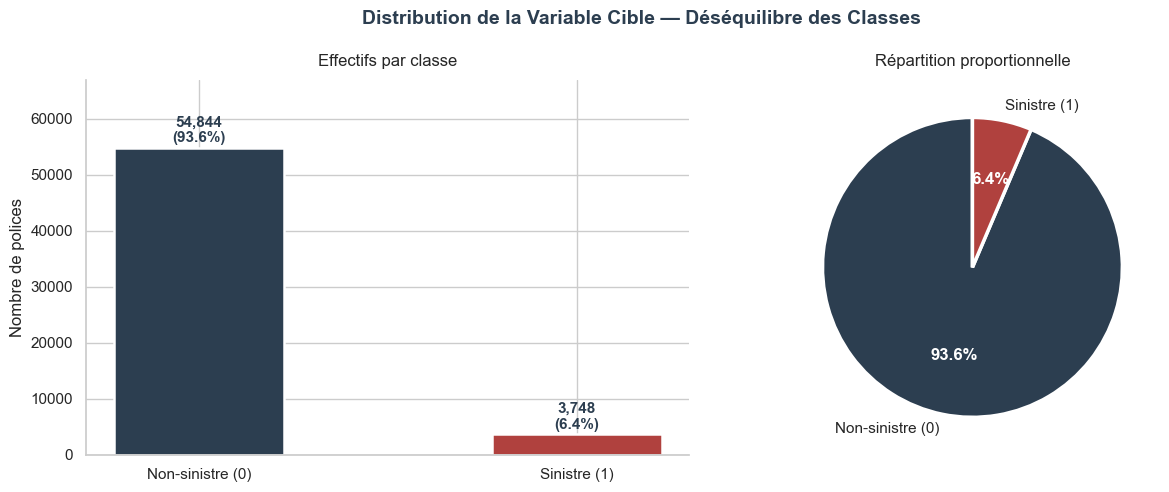

In [3]:
from scipy.stats import binomtest

counts = df['claim_status'].value_counts().sort_index()
total  = len(df)
p_obs  = counts[1] / total

# Test binomial H0 : P(sinistre) = 0.5
binom_result = binomtest(counts[1], total, p=0.5, alternative='two-sided')

print("=" * 55)
print(f"  Classe 0 (Non-sinistre) : {counts[0]:,} ({counts[0]/total*100:.2f}%)")
print(f"  Classe 1 (Sinistre)     : {counts[1]:,} ({counts[1]/total*100:.2f}%)")
print(f"  Ratio déséquilibre      : 1 sinistre / {int(counts[0]/counts[1])} non-sinistres")
print(f"  Test binomial p-value   : {binom_result.pvalue:.2e}  → rejet de H0")
print(f"  ⚠️  Déséquilibre statistiquement certain → traitement obligatoire")
print("=" * 55)

# ── Visualisation ─────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle("Distribution de la Variable Cible — Déséquilibre des Classes",
             fontsize=14, fontweight='bold', color=DARK)

# Barplot
ax = axes[0]
bars = ax.bar(['Non-sinistre (0)', 'Sinistre (1)'],
              counts.values, color=[DARK, RED],
              width=0.45, edgecolor='white', linewidth=1.8)
ax.set_title("Effectifs par classe", pad=10)
ax.set_ylabel("Nombre de polices")
ax.set_ylim(0, counts.max() * 1.22)
for bar, cnt in zip(bars, counts.values):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+400,
            f'{cnt:,}\n({cnt/total*100:.1f}%)',
            ha='center', va='bottom', fontweight='bold', color=DARK, fontsize=11)
ax.spines[['top','right']].set_visible(False)

# Pie
ax2 = axes[1]
wedges, texts, ats = ax2.pie(
    counts.values, labels=['Non-sinistre (0)', 'Sinistre (1)'],
    colors=[DARK, RED], autopct='%1.1f%%', startangle=90,
    wedgeprops={'edgecolor':'white','linewidth':2.5})
for at in ats:
    at.set(color='white', fontweight='bold', fontsize=12)
ax2.set_title("Répartition proportionnelle", pad=10)

plt.tight_layout()
plt.show()

### 1.3 Statistiques descriptives — Variables quantitatives

In [4]:
all_quanti = quanti_cols + quanti_disc
desc = df[all_quanti].describe().T
desc['skewness'] = df[all_quanti].skew()
desc['kurtosis'] = df[all_quanti].kurt()
print("Statistiques descriptives des variables quantitatives :")
print(desc[['mean','std','min','25%','50%','75%','max','skewness','kurtosis']].round(2).to_string())

Statistiques descriptives des variables quantitatives :
                         mean       std     min     25%     50%      75%      max  skewness  kurtosis
subscription_length      6.11      4.14     0.0     2.1     5.7     10.4     14.0      0.05     -1.50
vehicle_age              1.39      1.13     0.0     0.4     1.2      2.2     20.0      1.09      5.30
region_density       18826.86  17660.17   290.0  6112.0  8794.0  27003.0  73430.0      1.67      2.59
turning_radius           4.85      0.23     4.5     4.6     4.8      5.0      5.2      0.42     -1.18
length                3850.48    311.46  3445.0  3445.0  3845.0   3995.0   4300.0      0.15     -1.21
width                 1672.23    112.09  1475.0  1515.0  1735.0   1755.0   1811.0     -0.49     -1.44
gross_weight          1385.28    212.42  1051.0  1185.0  1335.0   1510.0   1720.0      0.55     -1.02
displacement          1162.36    266.30   796.0   796.0  1197.0   1493.0   1498.0     -0.11     -1.34
customer_age            44

### 1.4 Analyse des variables qualitatives

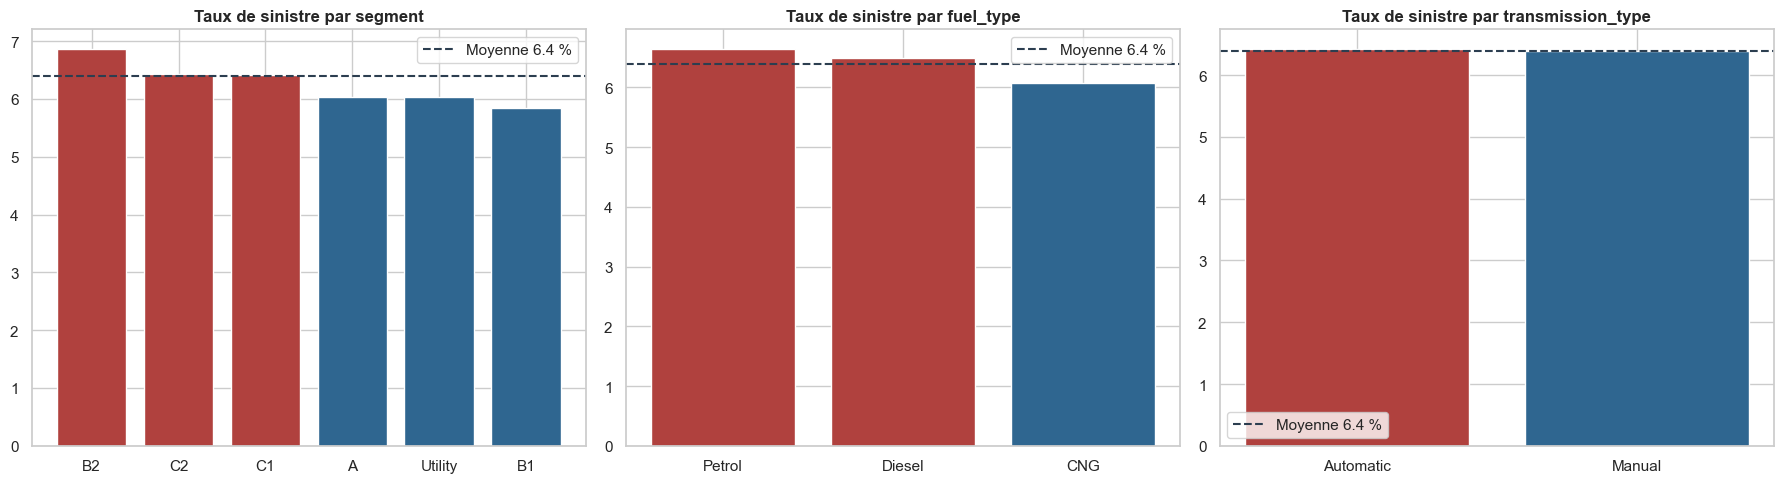

In [5]:
mean_global = df['claim_status'].mean() * 100
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col in zip(axes, ['segment', 'fuel_type', 'transmission_type']):
    taux = df.groupby(col)['claim_status'].mean().sort_values(ascending=False) * 100
    ax.bar(taux.index, taux.values, color=[RED if v > mean_global else BLUE for v in taux.values])
    ax.axhline(mean_global, color=DARK, ls='--', lw=1.5, label=f'Moyenne {mean_global:.1f} %')
    ax.set_title(f'Taux de sinistre par {col}', fontweight='bold')
    ax.legend()
plt.tight_layout()
plt.show()

### 1.5 Tests statistiques — Association variables vs cible

In [6]:
from scipy.stats import pointbiserialr, ttest_ind, shapiro, levene

results_stat = []
for col in quanti_cols + quanti_disc:
    d0 = df[df['claim_status']==0][col].dropna()
    d1 = df[df['claim_status']==1][col].dropna()
    r, p_pb    = pointbiserialr(df['claim_status'], df[col])
    t, p_welch = ttest_ind(d0, d1, equal_var=False)
    results_stat.append({
        'Variable'      : col,
        'Moy. Classe 0' : round(d0.mean(), 3),
        'Moy. Classe 1' : round(d1.mean(), 3),
        'Corr. PB'      : round(r, 4),
        'p-value Welch' : f'{p_welch:.2e}',
        'Significatif'  : '✅ Oui' if p_welch < 0.05 else '❌ Non'
    })

stat_df = pd.DataFrame(results_stat).sort_values('Corr. PB', key=abs, ascending=False)
print(stat_df.to_string(index=False))

           Variable  Moy. Classe 0  Moy. Classe 1  Corr. PB p-value Welch Significatif
subscription_length          6.026          7.359    0.0787      8.68e-87        ✅ Oui
        vehicle_age          1.397          1.266   -0.0282      4.74e-13        ✅ Oui
       customer_age         44.784         45.414    0.0222      1.61e-07        ✅ Oui
     region_density      18909.073      17623.820   -0.0178      2.84e-06        ✅ Oui
           cylinder          3.625          3.652    0.0134      9.85e-04        ✅ Oui
              width       1671.942       1676.499    0.0099      1.50e-02        ✅ Oui
       displacement       1161.821       1170.177    0.0077      6.10e-02        ❌ Non
             length       3849.948       3858.215    0.0065      1.13e-01        ❌ Non
       gross_weight       1385.061       1388.441    0.0039      3.42e-01        ❌ Non
        ncap_rating          1.759          1.780    0.0038      3.57e-01        ❌ Non
            airbags          3.136         

### 1.6 Tests de normalité (Shapiro-Wilk) & homogénéité (Levene)

In [7]:
# Tests sur sous-échantillon (Shapiro limité à 5000 obs)
sample = df.sample(2000, random_state=42)
normality_results = []
for col in quanti_cols[:6]:
    _, p_shap = shapiro(sample[col].dropna())
    d0 = df[df['claim_status']==0][col].dropna()
    d1 = df[df['claim_status']==1][col].dropna()
    _, p_lev  = levene(d0, d1)
    normality_results.append({
        'Variable'          : col,
        'p Shapiro-Wilk'    : f'{p_shap:.2e}',
        'Normalité ?'       : '❌ Non' if p_shap < 0.05 else '✅ Oui',
        'p Levene'          : f'{p_lev:.2e}',
        'Homoscédasticité ?' : '❌ Non' if p_lev < 0.05 else '✅ Oui'
    })

print(pd.DataFrame(normality_results).to_string(index=False))
print()
print("→ Normalité rejetée pour toutes les variables (p < 0.001)")
print("→ Avec n=58 592, le TCL garantit la robustesse asymptotique de LDA")
print("→ Homoscédasticité rejetée → LDA reste une approximation raisonnable")

           Variable p Shapiro-Wilk Normalité ? p Levene Homoscédasticité ?
subscription_length       7.59e-33       ❌ Non 1.45e-20              ❌ Non
        vehicle_age       2.70e-30       ❌ Non 1.60e-06              ❌ Non
     region_density       1.32e-46       ❌ Non 1.22e-06              ❌ Non
     turning_radius       7.69e-39       ❌ Non 1.21e-01              ✅ Oui
             length       1.38e-37       ❌ Non 1.11e-01              ✅ Oui
              width       1.80e-43       ❌ Non 2.63e-03              ❌ Non

→ Normalité rejetée pour toutes les variables (p < 0.001)
→ Avec n=58 592, le TCL garantit la robustesse asymptotique de LDA
→ Homoscédasticité rejetée → LDA reste une approximation raisonnable


### 1.7 Matrice de corrélation

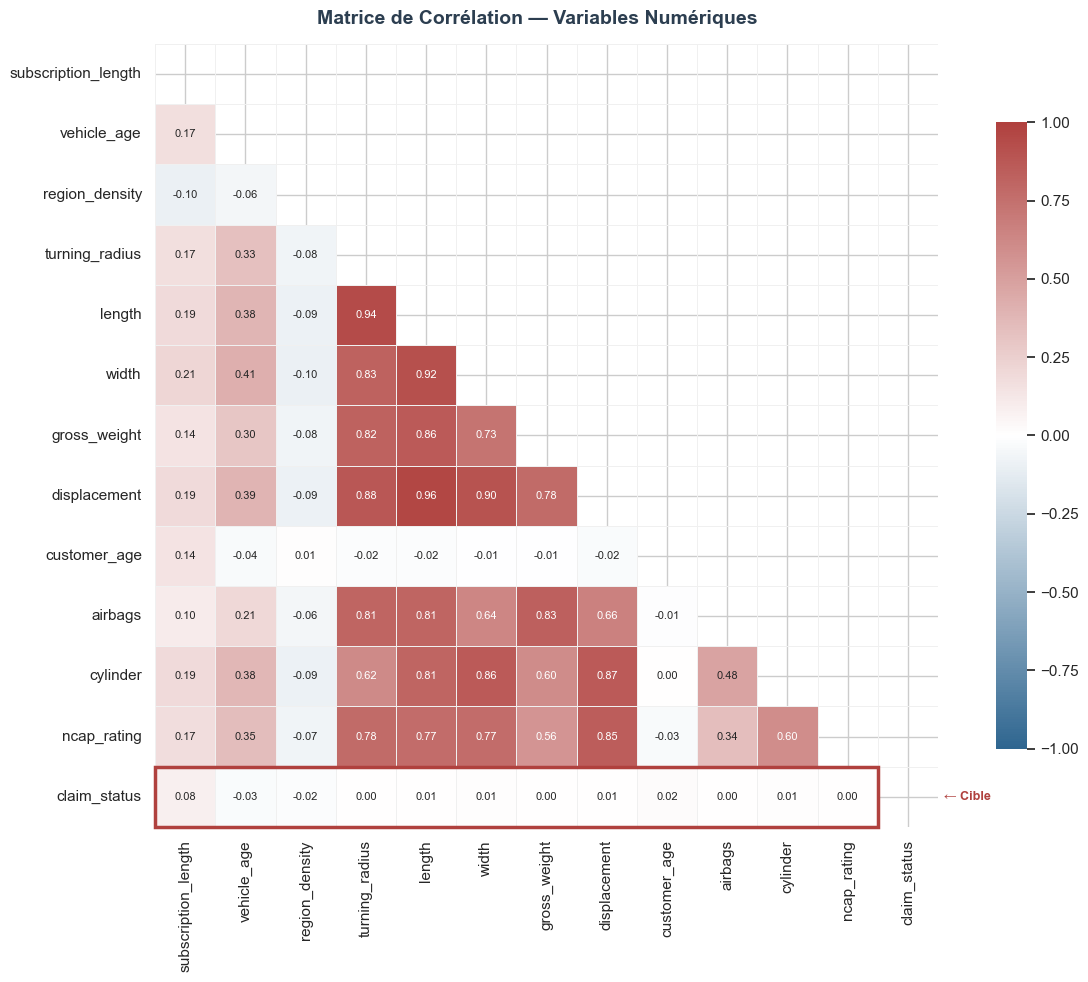

In [8]:
num_cols_corr = quanti_cols + quanti_disc + ['claim_status']
corr = df[num_cols_corr].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(13, 10))
fig.suptitle("Matrice de Corrélation — Variables Numériques",
             fontsize=14, fontweight='bold', color=DARK)
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f',
            cmap=CMAP_CORP, center=0, vmin=-1, vmax=1,
            linewidths=0.5, linecolor='#F0F0F0',
            annot_kws={'size': 8}, ax=ax, square=True,
            cbar_kws={'shrink':0.8})
# Mettre en évidence la ligne claim_status
idx_cs = list(corr.columns).index('claim_status')
ax.add_patch(plt.Rectangle((0, idx_cs), idx_cs, 1,
             fill=False, edgecolor=RED, lw=2.5, clip_on=False))
ax.text(len(corr)+0.1, idx_cs+0.5, '← Cible',
        va='center', fontsize=9, color=RED, fontweight='bold')
plt.tight_layout()
plt.show()

In [9]:
# Les caracteristiques techniques du vehicule dependent-elles seulement du modele ?
spec_cols = [c for c in df.columns if c not in ('policy_id', 'claim_status', 'subscription_length', 'vehicle_age',
                                                 'customer_age', 'region_code', 'region_density', 'model')]
determined = [c for c in spec_cols if df.groupby('model')[c].nunique().max() == 1]
print(df['model'].nunique(), 'modeles de vehicule')
print(len(determined), 'variables sur', len(spec_cols), 'sont entierement determinees par le modele :')
print(determined)

11 modeles de vehicule
33 variables sur 33 sont entierement determinees par le modele :
['segment', 'fuel_type', 'max_torque', 'max_power', 'engine_type', 'airbags', 'is_esc', 'is_adjustable_steering', 'is_tpms', 'is_parking_sensors', 'is_parking_camera', 'rear_brakes_type', 'displacement', 'cylinder', 'transmission_type', 'steering_type', 'turning_radius', 'length', 'width', 'gross_weight', 'is_front_fog_lights', 'is_rear_window_wiper', 'is_rear_window_washer', 'is_rear_window_defogger', 'is_brake_assist', 'is_power_door_locks', 'is_central_locking', 'is_power_steering', 'is_driver_seat_height_adjustable', 'is_day_night_rear_view_mirror', 'is_ecw', 'is_speed_alert', 'ncap_rating']


**Lecture :** presque toutes les caractéristiques techniques (dimensions, airbags, équipements…) sont **entièrement déterminées par le modèle du véhicule**. Elles n'apportent pas d'information nouvelle une fois le modèle connu. Elles sont fortement redondantes entre elles, d'où l'importance de l'étape de sélection.

L'information réellement propre à chaque police tient en quelques variables : l'ancienneté du contrat, l'âge du véhicule, l'âge du conducteur et la région.

---
## 2. Préparation

On sépare d'abord un jeu de **test (20 %)** qui ne sert qu'à l'évaluation finale. Tout ce qui s'apprend (encodages, standardisation, rééquilibrage, sélection, hyperparamètres, seuil) est appris **sur le train seulement**, à l'intérieur de pipelines.

| Type de variable | Traitement |
|---|---|
| Oui / Non (17 équipements) | 0 / 1 |
| `max_torque`, `max_power` (texte) | valeur numérique extraite (Nm, bhp) |
| Peu de modalités (`segment`, `fuel_type`, `engine_type`, `steering_type`, `transmission_type`, `rear_brakes_type`) | one-hot |
| Codes nombreux (`region_code` : 22 régions, `model` : 11 modèles) | encodage par la cible (taux de sinistre moyen), calculé en validation croisée interne |
| Numériques | standardisation (pour les modèles linéaires et le rééquilibrage) |

In [10]:
d = df.drop(columns='policy_id').copy()
d['max_torque_nm'] = d.pop('max_torque').str.extract(r'([\d.]+)Nm', expand=False).astype(float)
d['max_power_bhp'] = d.pop('max_power').str.extract(r'([\d.]+)bhp', expand=False).astype(float)
yes_no = [c for c in d.columns if d[c].dtype == object and set(d[c].dropna().unique()) <= {'Yes', 'No'}]
d[yes_no] = (d[yes_no] == 'Yes').astype(int)

# Variables creees
d['age_ratio'] = d['customer_age'] / (d['vehicle_age'] + 1)
d['safety_score'] = d['airbags'] * d['ncap_rating']
d['log_density'] = np.log1p(d['region_density'])
d['power_per_cylinder'] = d['max_power_bhp'] / d['cylinder']

X = d.drop(columns='claim_status')
y = d['claim_status'].astype(int)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)

onehot_cols = ['segment', 'fuel_type', 'engine_type', 'steering_type', 'transmission_type', 'rear_brakes_type']
target_cols = ['region_code', 'model']
print(len(yes_no), 'variables oui/non encodees en 0/1')
print('Train :', X_train.shape, f'{y_train.mean() * 100:.2f} % de sinistres | Test :', X_test.shape)

encoder = ColumnTransformer(
    [('onehot', OneHotEncoder(drop='if_binary', sparse_output=False, handle_unknown='ignore'), onehot_cols),
     ('cible', TargetEncoder(target_type='binary', random_state=SEED), target_cols)],
    remainder='passthrough', verbose_feature_names_out=False).set_output(transform='pandas')
X_train_enc = clone(encoder).fit_transform(X_train, y_train)
features_all = [str(c) for c in X_train_enc.columns]
print(len(features_all), 'variables apres encodage')


def make_pipe(model, cols, sampler='passthrough'):
    # encodage -> choix des colonnes -> standardisation -> reequilibrage -> modele
    return Pipeline([
        ('encode', clone(encoder)),
        ('select', ColumnTransformer([('keep', 'passthrough', list(cols))], remainder='drop',
                                     verbose_feature_names_out=False).set_output(transform='pandas')),
        ('scale', StandardScaler().set_output(transform='pandas')),
        ('sampler', sampler),
        ('model', model)])

17 variables oui/non encodees en 0/1
Train : (46873, 43) 6.40 % de sinistres | Test : (11719, 43)
62 variables apres encodage


---
## 3. Rééquilibrage : chaque méthode dans sa meilleure version

Seulement 6,4 % des polices ont un sinistre. Chaque méthode est **réglée** par validation croisée à 5 plis sur le train, puis les méthodes sont comparées dans leur meilleure version. Le modèle de référence est une régression logistique.

Le rééquilibrage est appliqué **à l'intérieur** de chaque pli, sur la partie entraînement seulement. La première version appliquait SMOTETomek avant la validation croisée : des polices synthétiques se retrouvaient dans les plis de validation, ce qui donnait une AUC de 0,89 en validation croisée contre 0,64 sur le test.

| Méthode | Paramètres réglés |
|---|---|
| Aucun | aucun |
| Pondération des classes | `class_weight='balanced'` |
| RandomUnderSampler | ratio final (0,25 / 0,5 / 1) |
| SMOTE | nombre de voisins (3 / 5 / 10), ratio (0,33 / 1) |
| ADASYN | nombre de voisins (3 / 5 / 10) |

                Methode    AUC  AUC_std  PR_AUC                                                     Parametres
     RandomUnderSampler 0.6063   0.0069  0.0881                           {'sampler__sampling_strategy': 0.25}
Ponderation des classes 0.6062   0.0077  0.0884                            {'model__class_weight': 'balanced'}
                  Aucun 0.6061   0.0075  0.0883                                                             {}
                 ADASYN 0.6058   0.0085  0.0885                                    {'sampler__n_neighbors': 3}
                  SMOTE 0.6058   0.0084  0.0884 {'sampler__k_neighbors': 3, 'sampler__sampling_strategy': 1.0}

Meilleure methode : RandomUnderSampler | proposee ensuite a chaque modele : ['str', 'RandomUnderSampler']


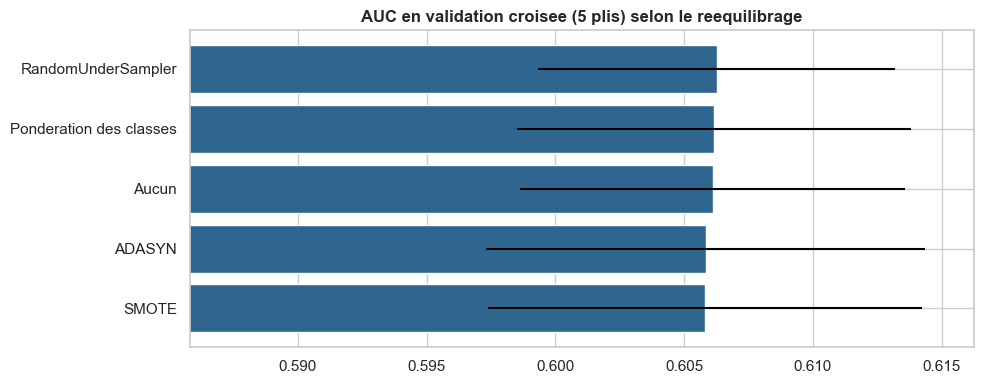

In [11]:
lr_ref = LogisticRegression(max_iter=3000)
sampling_methods = {
    'Aucun': ('passthrough', {}),
    'Ponderation des classes': ('passthrough', {'model__class_weight': ['balanced']}),
    'RandomUnderSampler': (RandomUnderSampler(random_state=SEED), {'sampler__sampling_strategy': [0.25, 0.5, 1.0]}),
    'SMOTE': (SMOTE(random_state=SEED), {'sampler__k_neighbors': [3, 5, 10], 'sampler__sampling_strategy': [0.33, 1.0]}),
    'ADASYN': (ADASYN(random_state=SEED), {'sampler__n_neighbors': [3, 5, 10]}),
}
rows, best_sampling_params = [], {}
for name, (sampler, grid) in sampling_methods.items():
    gs = GridSearchCV(make_pipe(clone(lr_ref), features_all, sampler), grid or [{}], cv=CV5,
                      scoring={'AUC': 'roc_auc', 'AP': 'average_precision'}, refit='AUC', n_jobs=-1).fit(X_train, y_train)
    i, r = gs.best_index_, gs.cv_results_
    best_sampling_params[name] = gs.best_params_
    rows.append({'Methode': name, 'AUC': r['mean_test_AUC'][i], 'AUC_std': r['std_test_AUC'][i],
                 'PR_AUC': r['mean_test_AP'][i], 'Parametres': gs.best_params_})
sampling_df = pd.DataFrame(rows).sort_values('AUC', ascending=False).reset_index(drop=True)
print(sampling_df.round(4).to_string(index=False))

best_sampling = sampling_df.loc[0, 'Methode']
params = {k.replace('sampler__', ''): v for k, v in best_sampling_params[best_sampling].items() if k.startswith('sampler__')}
makers = {'RandomUnderSampler': lambda: RandomUnderSampler(random_state=SEED, **params),
          'SMOTE': lambda: SMOTE(random_state=SEED, **params), 'ADASYN': lambda: ADASYN(random_state=SEED, **params)}
sampler_options = ['passthrough'] + ([makers[best_sampling]()] if best_sampling in makers else [])
print('\nMeilleure methode :', best_sampling, '| proposee ensuite a chaque modele :', [type(s).__name__ for s in sampler_options])

fig, ax = plt.subplots(figsize=(10, 4))
s = sampling_df.sort_values('AUC')
ax.barh(s['Methode'], s['AUC'], xerr=s['AUC_std'], color=BLUE)
ax.set_xlim(s['AUC'].min() - 0.02, s['AUC'].max() + 0.01)
ax.set_title('AUC en validation croisee (5 plis) selon le reequilibrage', fontweight='bold')
plt.tight_layout()
plt.savefig('figures/reequilibrage.png', dpi=150, bbox_inches='tight')
plt.show()

**Lecture.** Une fois réglées, les cinq approches donnent la **même AUC à 0,0005 près** (environ 0,606). Le rééquilibrage ne rend pas les sinistres plus prévisibles : il déplace seulement le seuil de décision, qui est réglé plus loin. Le sous-échantillonnage, légèrement devant, est proposé à chaque modèle comme une option parmi d'autres.

---
## 4. Sélection des variables : une méthode par modèle

| Modèle | Méthode | Pourquoi |
|---|---|---|
| AFD et régression logistique | **Stepwise forward** (AUC en validation croisée) | Méthode classique des modèles linéaires, qui écarte les variables redondantes |
| Arbre et forêt aléatoire | **RFECV** avec l'importance interne du modèle | Retire une à une les variables les moins utilisées ; le nombre final est choisi par validation croisée |
| XGBoost et LightGBM | **Importance par permutation** sur un jeu de validation | On garde une variable si la perte d'AUC quand on la mélange est nettement positive |

In [12]:
X_sel, y_sel = X_train_enc, y_train
sfs = SequentialFeatureSelector(SkPipeline([('sc', StandardScaler()), ('lr', LogisticRegression(max_iter=3000))]),
                                n_features_to_select='auto', tol=0.001, direction='forward', scoring='roc_auc',
                                cv=CV3, n_jobs=-1).fit(X_sel, y_sel)
features_linear = [str(c) for c in np.array(features_all)[sfs.get_support()]]
print('Lineaires (stepwise) :', features_linear)

rfe = {}
for name, est in [('Decision Tree', DecisionTreeClassifier(max_depth=6, min_samples_leaf=200, random_state=SEED)),
                  ('Random Forest', RandomForestClassifier(n_estimators=150, max_depth=10, min_samples_leaf=50,
                                                           random_state=SEED, n_jobs=-1))]:
    rfe[name] = RFECV(est, step=1, cv=CV3, scoring='roc_auc', min_features_to_select=3).fit(X_sel, y_sel)
    print(f'{name} (RFECV) :', [str(c) for c in np.array(features_all)[rfe[name].support_]])

X_fit, X_val, y_fit, y_val = train_test_split(X_sel, y_sel, test_size=0.3, stratify=y_sel, random_state=SEED)
xgb_sel = XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4, device=DEVICE, tree_method='hist',
                        random_state=SEED, eval_metric='auc').fit(X_fit, y_fit)
perm = permutation_importance(xgb_sel, X_val, y_val, scoring='roc_auc', n_repeats=10, random_state=SEED)
perm_df = pd.DataFrame({'Importance': perm.importances_mean, 'Ecart_type': perm.importances_std}, index=features_all)
features_boost = [f for f in features_all if perm_df.loc[f, 'Importance'] - 2 * perm_df.loc[f, 'Ecart_type'] > 0]
print('Boosting (permutation) :', features_boost)

features_by_model = {'AFD': features_linear, 'Logistic Regression': features_linear,
                     'Decision Tree': [str(c) for c in np.array(features_all)[rfe['Decision Tree'].support_]],
                     'Random Forest': [str(c) for c in np.array(features_all)[rfe['Random Forest'].support_]],
                     'XGBoost': features_boost, 'LightGBM': features_boost}
print('\nNombre de variables :', {m: len(c) for m, c in features_by_model.items()})

Lineaires (stepwise) : ['region_code', 'subscription_length', 'age_ratio']


Decision Tree (RFECV) : ['region_code', 'subscription_length', 'vehicle_age', 'length', 'gross_weight', 'age_ratio', 'log_density']


Random Forest (RFECV) : ['segment_A', 'segment_B2', 'engine_type_F8D Petrol Engine', 'steering_type_Electric', 'transmission_type_Manual', 'region_code', 'model', 'subscription_length', 'vehicle_age', 'customer_age', 'region_density', 'is_parking_camera', 'displacement', 'turning_radius', 'length', 'width', 'gross_weight', 'is_brake_assist', 'ncap_rating', 'max_torque_nm', 'max_power_bhp', 'age_ratio', 'safety_score', 'log_density', 'power_per_cylinder']


Boosting (permutation) : ['segment_B1', 'engine_type_F8D Petrol Engine', 'subscription_length', 'vehicle_age', 'cylinder', 'turning_radius', 'gross_weight', 'age_ratio']

Nombre de variables : {'AFD': 3, 'Logistic Regression': 3, 'Decision Tree': 7, 'Random Forest': 25, 'XGBoost': 8, 'LightGBM': 8}


**Lecture.**
- Le **stepwise** ne garde que **3 variables** pour les modèles linéaires : la région, l'ancienneté du contrat et le rapport âge du conducteur / âge du véhicule.
- Les méthodes des modèles d'arbres en gardent davantage : **7** pour l'arbre, **25** pour la forêt aléatoire, **8** pour les modèles de boosting.

Comme vu en exploration, la plupart des caractéristiques techniques ne font que répéter le modèle du véhicule. Elles sont redondantes, et les méthodes de sélection les écartent presque toutes.

---
## 5. Modèles : par défaut, puis réglés

1. **Par défaut** : chaque modèle, avec toutes les variables et ses paramètres par défaut, évalué en validation croisée à 5 plis sur le train.
2. **Réglé** : recherche aléatoire d'hyperparamètres (graine fixe, validation croisée à 3 plis sur le train), avec les variables propres au modèle. La recherche choisit aussi le traitement du déséquilibre : rien, pondération des classes ou la meilleure méthode de la section 3.
3. **Seuil** : les prédictions hors échantillon du train (5 plis) donnent le seuil qui maximise le F1. Le test ne sert qu'à la fin.

In [13]:
pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
models = {
    'AFD': (LinearDiscriminantAnalysis(), 15, {'model__solver': ['lsqr'], 'model__shrinkage': [None, 'auto', 0.01, 0.1, 0.3, 0.6]}),
    'Logistic Regression': (LogisticRegression(max_iter=3000, solver='liblinear'), 30,
                            {'model__C': loguniform(1e-3, 1e2), 'model__penalty': ['l1', 'l2'], 'model__class_weight': [None, 'balanced']}),
    'Decision Tree': (DecisionTreeClassifier(random_state=SEED), 40,
                      {'model__max_depth': randint(3, 15), 'model__min_samples_leaf': randint(20, 1000),
                       'model__criterion': ['gini', 'entropy'], 'model__class_weight': [None, 'balanced']}),
    'Random Forest': (RandomForestClassifier(random_state=SEED, n_jobs=-1), 25,
                      {'model__n_estimators': [200, 400], 'model__max_depth': [6, 10, 14, None],
                       'model__min_samples_leaf': [10, 30, 100, 300], 'model__max_features': ['sqrt', 0.5],
                       'model__class_weight': [None, 'balanced_subsample']}),
    'XGBoost': (XGBClassifier(device=DEVICE, tree_method='hist', random_state=SEED, eval_metric='auc'), 40,
                {'model__n_estimators': randint(200, 1200), 'model__learning_rate': loguniform(0.005, 0.2),
                 'model__max_depth': randint(2, 8), 'model__min_child_weight': loguniform(1, 50),
                 'model__subsample': uniform(0.6, 0.4), 'model__colsample_bytree': uniform(0.5, 0.5),
                 'model__reg_lambda': loguniform(0.1, 50), 'model__scale_pos_weight': [1, pos_weight ** 0.5, pos_weight]}),
    'LightGBM': (LGBMClassifier(random_state=SEED, verbose=-1, n_jobs=4), 40,
                 {'model__n_estimators': randint(200, 1200), 'model__learning_rate': loguniform(0.005, 0.2),
                  'model__num_leaves': randint(7, 64), 'model__min_child_samples': randint(20, 400),
                  'model__subsample': uniform(0.6, 0.4), 'model__subsample_freq': [1],
                  'model__colsample_bytree': uniform(0.5, 0.5), 'model__reg_lambda': loguniform(0.1, 50),
                  'model__class_weight': [None, 'balanced']}),
}

before = {}
for name, (model, _, _) in models.items():
    r = cross_validate(make_pipe(clone(model), features_all), X_train, y_train, cv=CV5, scoring='roc_auc',
                       n_jobs=1 if name in ('XGBoost', 'Random Forest', 'LightGBM') else -1)
    before[name] = r['test_score'].mean()
    print(f'{name:<20} AUC par defaut = {before[name]:.4f}')

AFD                  AUC par defaut = 0.6065


Logistic Regression  AUC par defaut = 0.6062


Decision Tree        AUC par defaut = 0.5109


Random Forest        AUC par defaut = 0.5779


XGBoost              AUC par defaut = 0.6073


LightGBM             AUC par defaut = 0.6337


In [14]:
def oof_threshold(pipe):
    oof, fold_auc = np.zeros(len(y_train)), []
    for tr, va in CV5.split(X_train, y_train):
        m = clone(pipe).fit(X_train.iloc[tr], y_train.iloc[tr])
        oof[va] = m.predict_proba(X_train.iloc[va])[:, 1]
        fold_auc.append(roc_auc_score(y_train.iloc[va], oof[va]))
    p, r, t = precision_recall_curve(y_train, oof)
    f1 = 2 * p[:-1] * r[:-1] / np.maximum(p[:-1] + r[:-1], 1e-12)
    return np.array(fold_auc), float(t[np.argmax(f1)])

tuned, results, probas, fold_aucs = {}, [], {}, {}
for name, (model, n_iter, space) in models.items():
    cols = features_by_model[name]
    rs = RandomizedSearchCV(make_pipe(clone(model), cols), dict(space, sampler=sampler_options), n_iter=n_iter, cv=CV3,
                            scoring='roc_auc', random_state=SEED,
                            n_jobs=1 if name in ('XGBoost', 'Random Forest', 'LightGBM') else -1).fit(X_train, y_train)
    pipe = clone(rs.best_estimator_)
    fold_auc, thr = oof_threshold(pipe)
    pipe.fit(X_train, y_train)
    prob = pipe.predict_proba(X_test)[:, 1]
    pred = (prob >= thr).astype(int)
    tuned[name], probas[name], fold_aucs[name] = pipe, prob, fold_auc
    results.append({'Modele': name, 'Nb variables': len(cols), 'AUC defaut (CV)': before[name],
                    'AUC reglee (CV)': fold_auc.mean(), 'Ecart-type CV': fold_auc.std(), 'Seuil': thr,
                    'AUC test': roc_auc_score(y_test, prob), 'PR-AUC test': average_precision_score(y_test, prob),
                    'Rappel': recall_score(y_test, pred), 'Precision': precision_score(y_test, pred), 'F1': f1_score(y_test, pred)})
    shown = {k: (type(v).__name__ if k == 'sampler' and v != 'passthrough' else v) for k, v in rs.best_params_.items()}
    print(f"{name:<20} AUC CV = {fold_auc.mean():.4f} | test = {results[-1]['AUC test']:.4f} | {shown}")

results_df = pd.DataFrame(results).set_index('Modele')
print()
print(results_df.round(4).to_string())

AFD                  AUC CV = 0.6062 | test = 0.6221 | {'sampler': 'RandomUnderSampler', 'model__solver': 'lsqr', 'model__shrinkage': 0.6}


Logistic Regression  AUC CV = 0.6065 | test = 0.6213 | {'model__C': np.float64(0.0011649969967638908), 'model__class_weight': None, 'model__penalty': 'l2', 'sampler': 'RandomUnderSampler'}


Decision Tree        AUC CV = 0.6323 | test = 0.6501 | {'model__class_weight': 'balanced', 'model__criterion': 'entropy', 'model__max_depth': 5, 'model__min_samples_leaf': 681, 'sampler': 'passthrough'}


Random Forest        AUC CV = 0.6534 | test = 0.6665 | {'sampler': 'RandomUnderSampler', 'model__n_estimators': 400, 'model__min_samples_leaf': 10, 'model__max_features': 0.5, 'model__max_depth': 6, 'model__class_weight': None}


XGBoost              AUC CV = 0.6535 | test = 0.6600 | {'model__colsample_bytree': np.float64(0.6280341613806619), 'model__learning_rate': np.float64(0.005804262434469441), 'model__max_depth': 3, 'model__min_child_weight': np.float64(1.1045524260304713), 'model__n_estimators': 660, 'model__reg_lambda': np.float64(0.35029511132629426), 'model__scale_pos_weight': np.float64(14.634756504336224), 'model__subsample': np.float64(0.7901480892728447), 'sampler': 'passthrough'}


LightGBM             AUC CV = 0.6486 | test = 0.6498 | {'model__class_weight': None, 'model__colsample_bytree': np.float64(0.8553314448428937), 'model__learning_rate': np.float64(0.007527031816126454), 'model__min_child_samples': 399, 'model__n_estimators': 660, 'model__num_leaves': 57, 'model__reg_lambda': np.float64(0.12157000356394407), 'model__subsample': np.float64(0.8545641645055122), 'model__subsample_freq': 1, 'sampler': 'RandomUnderSampler'}

                     Nb variables  AUC defaut (CV)  AUC reglee (CV)  Ecart-type CV   Seuil  AUC test  PR-AUC test  Rappel  Precision      F1
Modele                                                                                                                                      
AFD                             3           0.6065           0.6062         0.0078  0.1963    0.6221       0.0916  0.6347     0.0847  0.1495
Logistic Regression             3           0.6062           0.6065         0.0076  0.2764    0.6213       0.0912  0.5320

Meilleur modele (AUC en validation croisee sur le train) : XGBoost


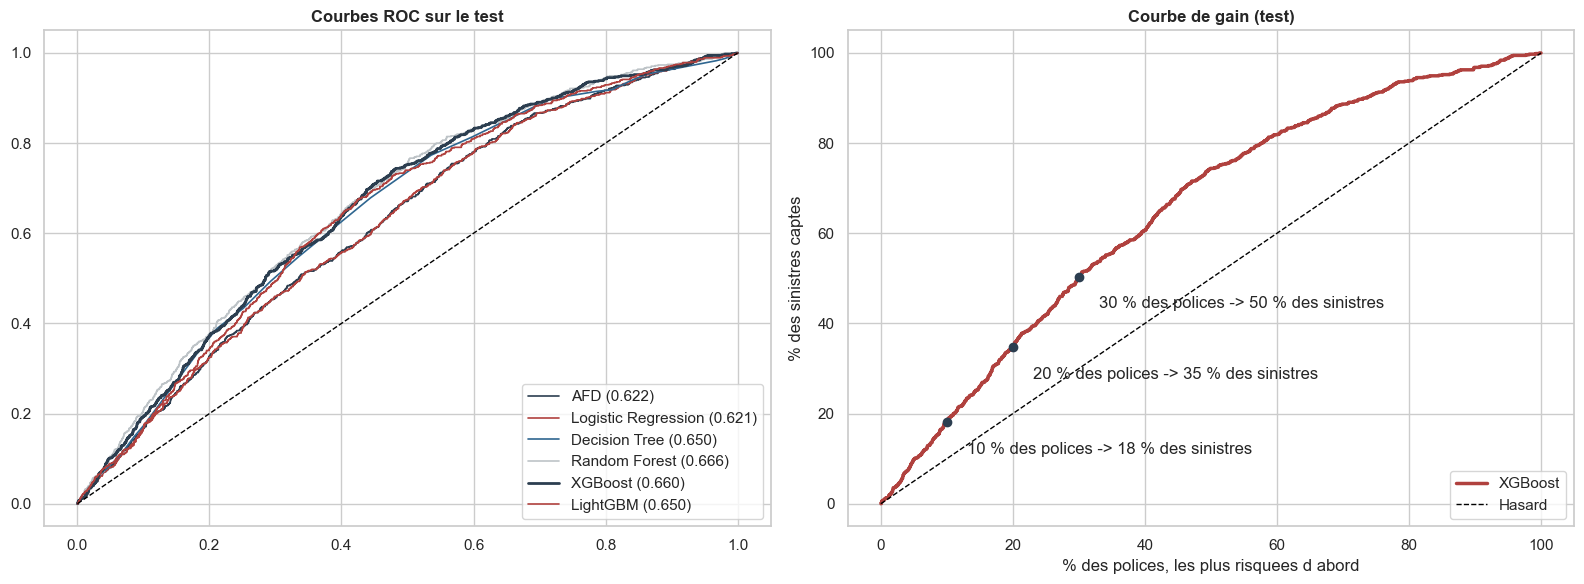

In [15]:
best = results_df['AUC reglee (CV)'].idxmax()
print('Meilleur modele (AUC en validation croisee sur le train) :', best)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for name, prob in probas.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    axes[0].plot(fpr, tpr, lw=2 if name == best else 1.2, label=f'{name} ({roc_auc_score(y_test, prob):.3f})')
axes[0].plot([0, 1], [0, 1], 'k--', lw=1)
axes[0].set_title('Courbes ROC sur le test', fontweight='bold')
axes[0].legend(loc='lower right')

prob = probas[best]
order = np.argsort(-prob)
captured = np.cumsum(y_test.values[order]) / y_test.sum()
share = np.arange(1, len(prob) + 1) / len(prob)
axes[1].plot(share * 100, captured * 100, color=RED, lw=2.5, label=best)
axes[1].plot([0, 100], [0, 100], 'k--', lw=1, label='Hasard')
for p in (10, 20, 30):
    c = captured[int(len(prob) * p / 100) - 1] * 100
    axes[1].scatter(p, c, color=DARK, zorder=3)
    axes[1].annotate(f'{p} % des polices -> {c:.0f} % des sinistres', (p, c), xytext=(p + 3, c - 7))
axes[1].set_xlabel('% des polices, les plus risquees d abord')
axes[1].set_ylabel('% des sinistres captes')
axes[1].set_title('Courbe de gain (test)', fontweight='bold')
axes[1].legend(loc='lower right')
plt.tight_layout()
plt.savefig('figures/roc_gain.png', dpi=150, bbox_inches='tight')
plt.show()

**Lecture.**
- **Le réglage améliore surtout les modèles d'arbres** : l'arbre de décision passe de 0,51 à 0,63 d'AUC en validation croisée, et la forêt aléatoire de 0,58 à 0,65.
- **XGBoost** (0,654) et la **forêt aléatoire** (0,653) arrivent à égalité. Sur le test, l'AUC va de 0,62 à 0,67 selon le modèle.
- **Usage concret** : en ciblant les 30 % de polices jugées les plus risquées, on capte la moitié des sinistres. C'est utile pour orienter la prévention, mais insuffisant pour tarifer police par police.
- **Plafond de performance** : la survenance d'un sinistre dépend surtout de facteurs absents des données (comportement de conduite, kilométrage, historique de sinistres). Aucun réglage ne peut compenser cette information manquante.

---
## 6. Interprétation du meilleur modèle

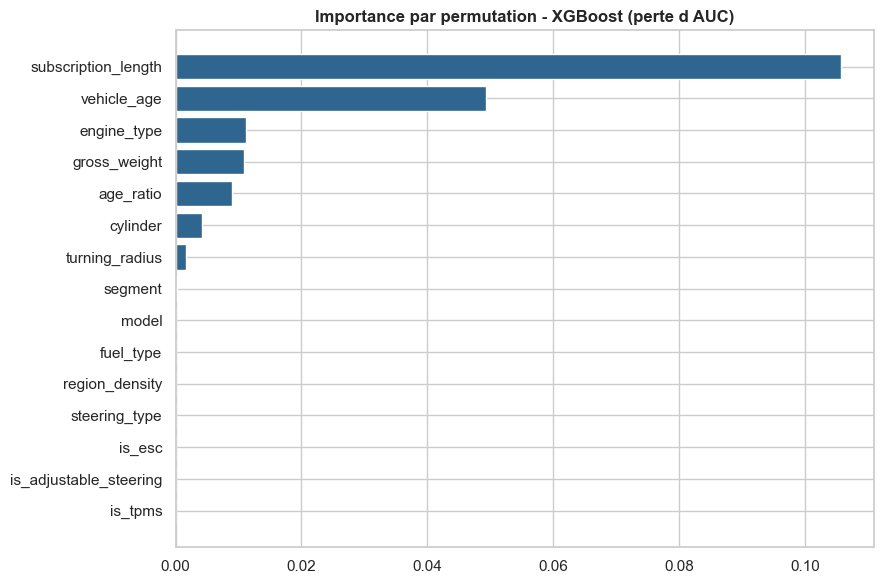

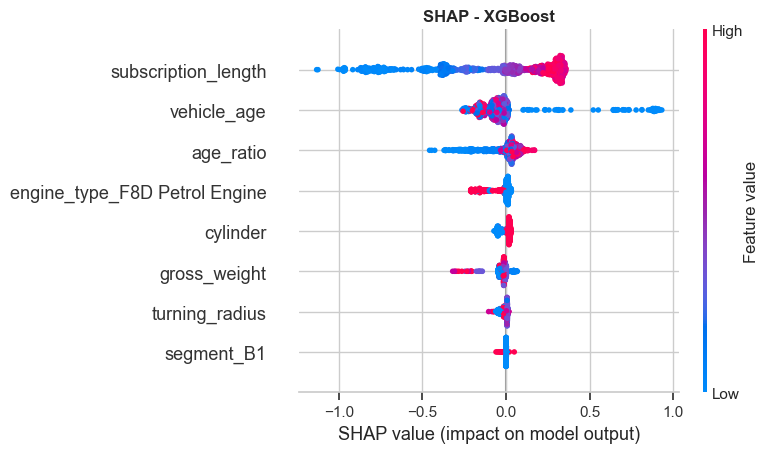

In [16]:
pipe = tuned[best]
X_imp = X_test.sample(min(5000, len(X_test)), random_state=SEED)
pi = permutation_importance(pipe, X_imp, y_test.loc[X_imp.index], scoring='roc_auc', n_repeats=10, random_state=SEED)
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values().tail(15)

pre = SkPipeline([(n, s) for n, s in pipe.steps if n not in ('sampler', 'model')])
model = pipe.named_steps['model']
Xt = pre.transform(X_imp.iloc[:1000])
explainer = shap.TreeExplainer(model) if best in ('XGBoost', 'LightGBM', 'Random Forest', 'Decision Tree') \
    else shap.LinearExplainer(model, Xt)
sv = explainer.shap_values(Xt)
sv = sv[1] if isinstance(sv, list) else (sv[:, :, 1] if np.ndim(sv) == 3 else sv)

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(imp.index, imp.values, color=BLUE)
ax.set_title(f'Importance par permutation - {best} (perte d AUC)', fontweight='bold')
plt.tight_layout()
plt.savefig('figures/importance.png', dpi=150, bbox_inches='tight')
plt.show()
plt.figure()
shap.summary_plot(sv, Xt, show=False, max_display=12)
plt.title(f'SHAP - {best}', fontweight='bold')
plt.tight_layout()
plt.show()

**Lecture.** Deux variables dominent :
- **l'ancienneté du contrat** (`subscription_length`) : plus une police est ancienne, plus elle a eu le temps de connaître un sinistre. C'est un effet d'**exposition**, à prendre en compte en tarification en raisonnant en fréquence par année-police ;
- **l'âge du véhicule** : les véhicules récents ont plus de sinistres déclarés.

Les caractéristiques techniques du véhicule n'apportent presque rien au-delà de ces deux variables.

## 7. Conclusion

| | Première version | Cette version |
|---|---|---|
| Rééquilibrage | SMOTETomek avant la validation croisée : 0,89 d'AUC en validation croisée, contre 0,64 sur le test | Appliqué dans chaque pli et réglé : validation croisée et test cohérents (0,65 et 0,66) |
| Seuil | Choisi sur le test | Choisi sur le train |
| Encodage | Codes de région et de modèle traités comme des nombres | One-hot ou encodage par la cible selon le type de variable |
| Modèles | 8 modèles et PyCaret, grilles de 10 essais | 6 modèles réglés par recherche aléatoire de 15 à 40 essais, XGBoost sur carte graphique |

**À retenir :**
- un sinistre automobile reste **difficile à prévoir** à partir de la seule fiche police et véhicule (AUC d'environ 0,65) ;
- l'information utile tient en peu de variables : l'ancienneté du contrat et l'âge du véhicule ;
- les données de conduite (télématique) et l'historique de sinistres permettraient d'aller plus loin.